# Lab 1: Introduction

## Objective
Become familiar with a dataset provided by scikit-learn, inspect its structure and summary statistics, separate features from the target, create training and testing subsets, and visualize the distribution of the target classes.

This introductory exercise uses the **Wine recognition dataset**. It contains numerical measurements of wines and a target class indicating the cultivar. The dataset is built into scikit-learn, so no separate download is needed.

## 1. Import libraries

The libraries below provide tools for tabular data, numerical operations, plotting, loading the sample dataset, and splitting data into training and testing sets.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split

## 2. Load and inspect the dataset

`load_wine(as_frame=True)` returns the dataset in a Pandas-friendly format. The shape reports the number of rows and columns. `head()` previews records, `dtypes` shows each column type, and `describe()` summarizes numerical features using statistics such as mean, standard deviation, and quartiles.

In [2]:
wine = load_wine(as_frame=True)
df = wine.frame

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())
print("\nColumn names:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nSummary statistics:")
display(df.describe().round(2))

Dataset shape: (178, 14)

First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0



Column names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'target']

Data types:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

Summary statistics:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89,0.94
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91,0.78
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00,0.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50,0.00
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50,1.00
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00,2.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00,2.00


## 3. Separate features and target, then split the data

The target column contains the class label, while the remaining columns are input features. Keeping them separate is a standard preparation step before building a machine-learning model. The split reserves 20% of the records for testing. `random_state=42` makes the split reproducible, and `stratify=y` preserves the class proportions in both subsets.

In [3]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Feature matrix shape: (178, 13)
Target vector shape: (178,)
Training feature shape: (142, 13)
Testing feature shape: (36, 13)


## 4. Visualize the target classes

A bar chart shows how many records belong to each class. This helps check the class distribution before modelling. The target is encoded as integers, so the next cell also prints the corresponding class names.

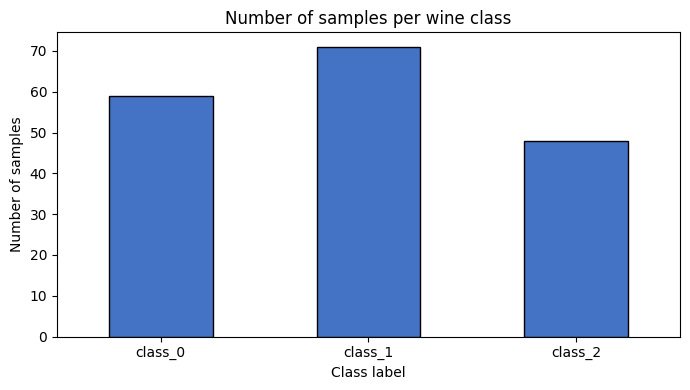

In [4]:
class_counts = df["target"].value_counts().sort_index()
ax = class_counts.plot(kind="bar", figsize=(7, 4), color="#4472C4", edgecolor="black")
ax.set_title("Number of samples per wine class")
ax.set_xlabel("Class label")
ax.set_ylabel("Number of samples")
ax.set_xticklabels([wine.target_names[i] for i in class_counts.index], rotation=0)
plt.tight_layout()
plt.show()

## 5. Interpret the target labels

The target values are numeric codes. This cell maps each code to its descriptive class name so that later results can be interpreted correctly.

In [5]:
print("Target labels:")
for i, name in enumerate(wine.target_names):
    print(f"{i}: {name}")

Target labels:
0: class_0
1: class_1
2: class_2


## Conclusion

The dataset was loaded and inspected, its numerical columns and target were identified, and the records were divided into training and testing subsets. The class-count chart confirms that the dataset contains three wine classes. These steps establish a basic workflow for later classification experiments.